<a href="https://colab.research.google.com/github/tlh222k/aio/blob/main/M4/foundational-deep-learning/01-linear-regression/code/06-one-sample-vectorization.ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 3.2 Gom tham số vào vector

Đặt

$$\hat y=wx+b,\qquad \boldsymbol x=\begin{bmatrix}1\\x\end{bmatrix},\qquad \boldsymbol\theta=\begin{bmatrix}b\\w\end{bmatrix}\;\Rightarrow\;\boldsymbol\theta^T=[b\;\;w]$$

thì $\hat y = wx+b\cdot 1=[b\;\;w]\begin{bmatrix}1\\x\end{bmatrix}=\boldsymbol\theta^T\boldsymbol x$ — một **dot product**.

Loss $L(\hat y,y)=(\hat y-y)^2$ chỉ làm việc với các **con số** nên giữ nguyên.

<p align="center">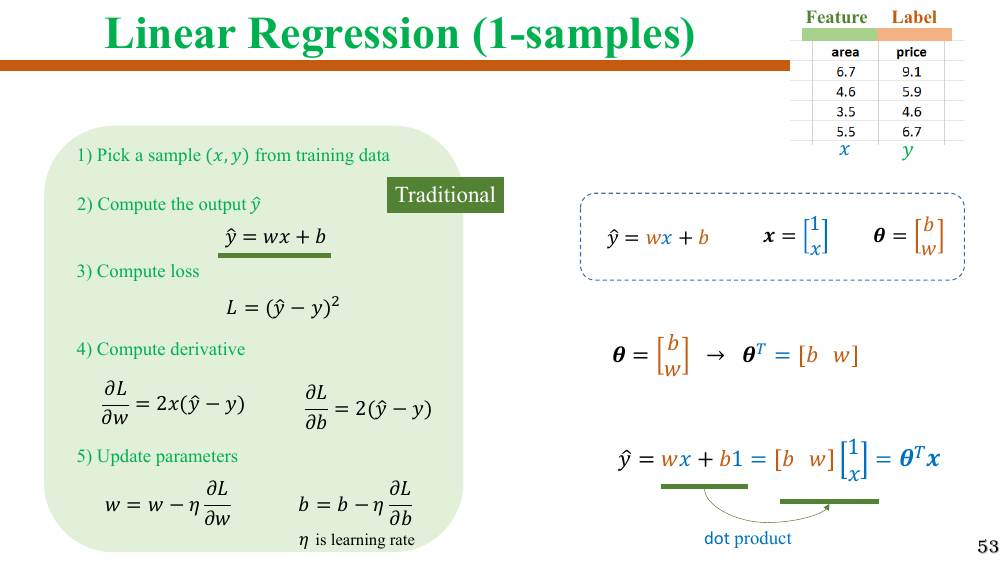<br/><sub><i>Slide trang 55 - Từ ŷ = wx + b đến ŷ = θᵀx</i></sub></p>

<p align="center">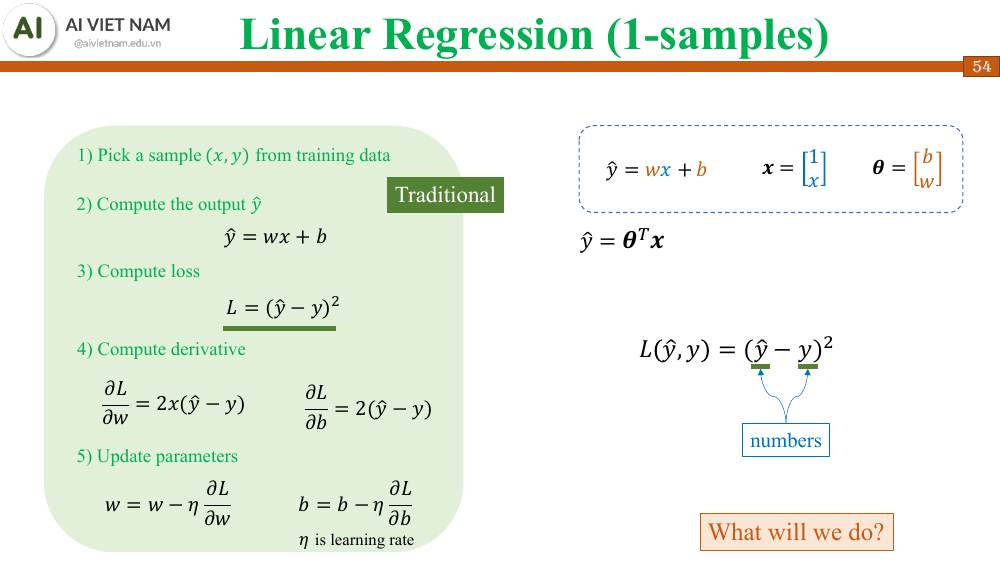<br/><sub><i>Slide trang 56 - Loss chỉ dùng số → What will we do?</i></sub></p>

## 3.3 Đạo hàm theo vector — gradient $\nabla_{\boldsymbol\theta}L$

Cả hai đạo hàm riêng có chung thừa số $2(\hat y-y)$:

$$\frac{\partial L}{\partial b}=2(\hat y-y)\times 1,\qquad \frac{\partial L}{\partial w}=2(\hat y-y)\times x
\;\Rightarrow\;
\nabla_{\boldsymbol\theta}L=\begin{bmatrix}\partial L/\partial b\\ \partial L/\partial w\end{bmatrix}=2(\hat y-y)\begin{bmatrix}1\\x\end{bmatrix}=2\boldsymbol x(\hat y-y)$$

<p align="center">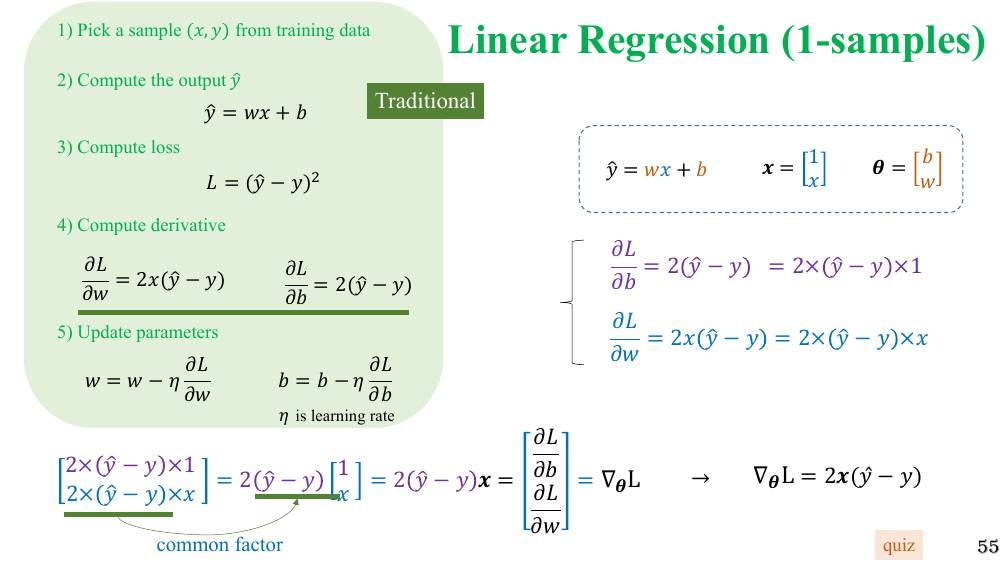<br/><sub><i>Slide trang 57 - Common factor 2(ŷ - y)</i></sub></p>

Cập nhật tham số cũng gộp lại:

$$b=b-\eta\frac{\partial L}{\partial b},\; w=w-\eta\frac{\partial L}{\partial w}\;\Longrightarrow\;\boldsymbol\theta=\boldsymbol\theta-\eta\nabla_{\boldsymbol\theta}L$$

<p align="center">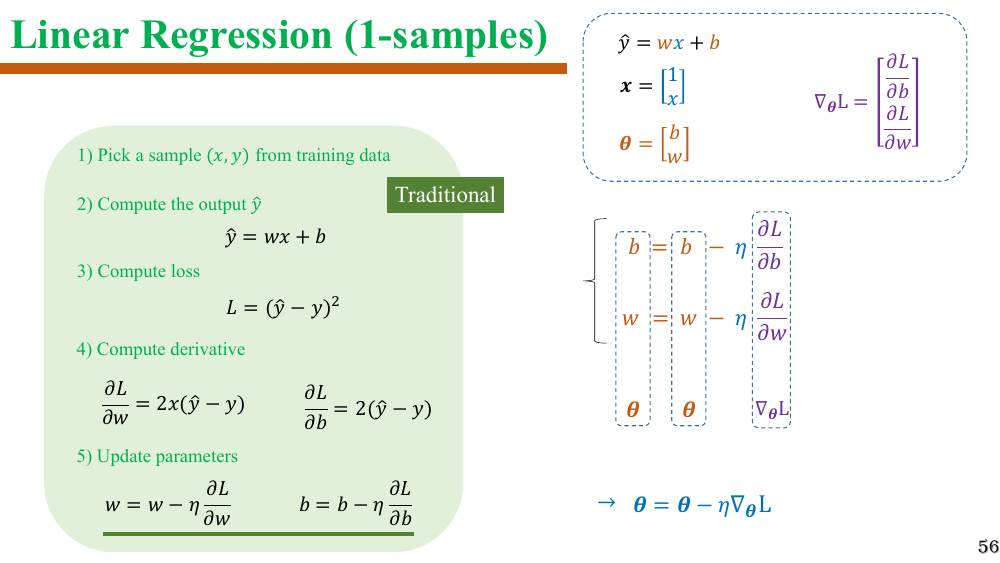<br/><sub><i>Slide trang 58 - θ = θ - η∇θL</i></sub></p>

<p align="center">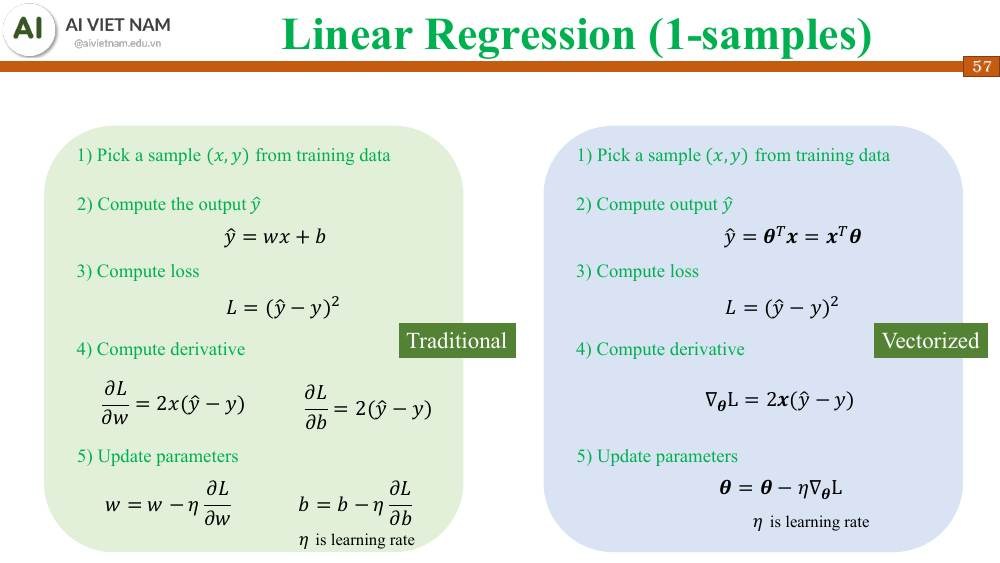<br/><sub><i>Slide trang 59 - Traditional vs Vectorized</i></sub></p>

<p align="center">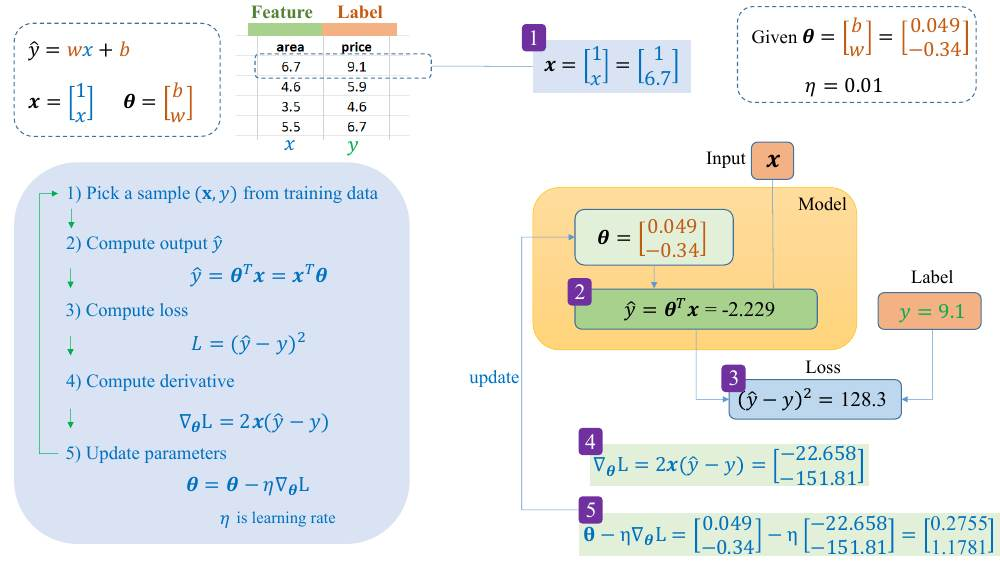<br/><sub><i>Slide trang 60 - Vectorized worked example</i></sub></p>

---------------------------

In [ ]:
!curl -l -o data.csv https://raw.githubusercontent.com/tlh222k/aio/refs/heads/main/data/data.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100    31  100    31    0     0    129      0 --:--:-- --:--:-- --:--:--   129


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random

In [ ]:
data = np.genfromtxt("/content/data.csv", delimiter=",")
data

array([[6.7, 9.1],
       [4.6, 5.9],
       [3.5, 4.6],
       [5.5, 6.7]])

In [134]:
def predict(x, theta):
  return x.T.dot(theta)  # theta.T.dot(x)

def compute_loss(y_hat, y):
  return (y_hat - y)**2

def compute_gradient(X,y_hat, y):
  return 2*X*(y_hat - y)

def update_parameters(theta, d_theta, learning_rate):
  return theta - learning_rate*d_theta


In [132]:
N = data.shape[0]
areas  = data[:, 0].reshape(1, N)
prices  = data[:, -1].reshape(N, )

X = np.vstack([np.ones((1, N)), areas]) # each sample is a column

print(f"areas.shape: {areas.shape}" )
print(f"prices.shape: {prices.shape}" )
print(f"N: {N}")
print(f"X: {X}")

areas.shape: (1, 4)
prices.shape: (4,)
N :4
X: [[1.  1.  1.  1. ]
 [6.7 4.6 3.5 5.5]]


In [141]:
epoch_max = 10
theta = np.array([0.049, -0.34])
lr = 0.01

losses = []
for _ in range(epoch_max):
  for i in range(N):
    x = X[:, i]
    y = prices[i]

    y_hat = predict(x, theta)

    loss = compute_loss(y_hat, y)
    losses.append(loss)

    d_theta = compute_gradient(x, y_hat, y)
    theta = update_parameters(theta, d_theta, lr)

print(f"losses: {losses}")
print(f"theta: {theta}")

losses: [np.float64(128.34624100000002), np.float64(0.042117054355360214), np.float64(0.017143255451757537), np.float64(0.046668355048423614), np.float64(0.8102642031279953), np.float64(0.15189122342145844), np.float64(0.015167536202538833), np.float64(0.25760117839621605), np.float64(0.587449014693501), np.float64(0.1565668474161118), np.float64(0.015484171012711736), np.float64(0.2621507903721882), np.float64(0.5825573177153622), np.float64(0.15537809860052929), np.float64(0.015010928840951116), np.float64(0.2629915543927167), np.float64(0.5802139181638774), np.float64(0.15412550290299254), np.float64(0.014537462343023595), np.float64(0.2637825444104964), np.float64(0.5779179814546943), np.float64(0.15288291543245522), np.float64(0.014073640908492906), np.float64(0.26457038452603016), np.float64(0.5756377945629113), np.float64(0.1516511707759244), np.float64(0.013619472137557253), np.float64(0.26535566755100237), np.float64(0.5733728429055963), np.float64(0.15043018252466867), np.flo

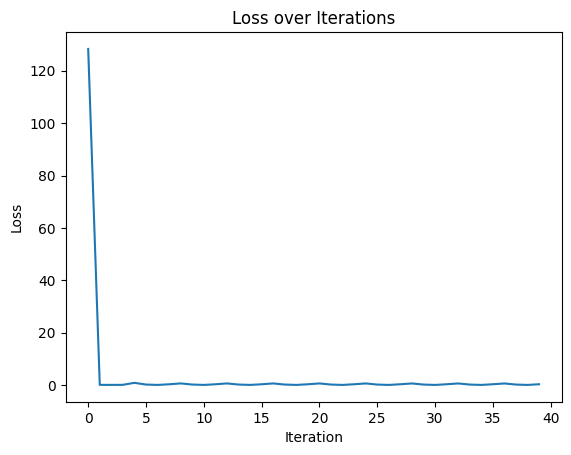

In [139]:
plt.plot(losses)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Loss over Iterations')
plt.show()


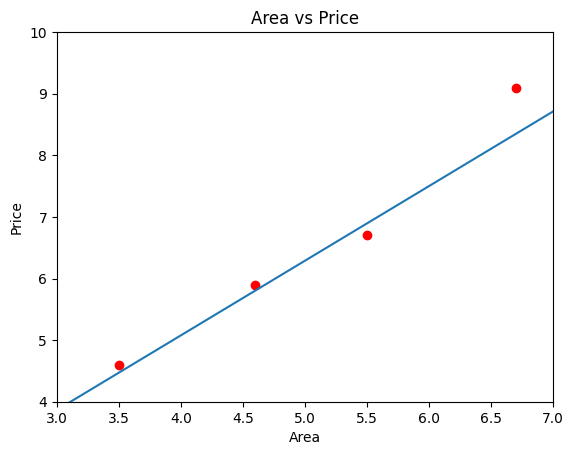

In [143]:
x_data = range(2, 8)

predicted_b, predicted_w = theta
y_data = [x*predicted_w + predicted_b for x in x_data]
plt.plot(x_data, y_data)
#--------------------------------------
plt.scatter(areas, prices, color='red')
plt.xlabel('Area')
plt.ylabel('Price')
plt.title('Area vs Price')
plt.xlim(3,7)
plt.ylim(4,10)
plt.show()